<a href="https://colab.research.google.com/github/wonjun605/AI/blob/main/Ch04_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(512, 512, 3)


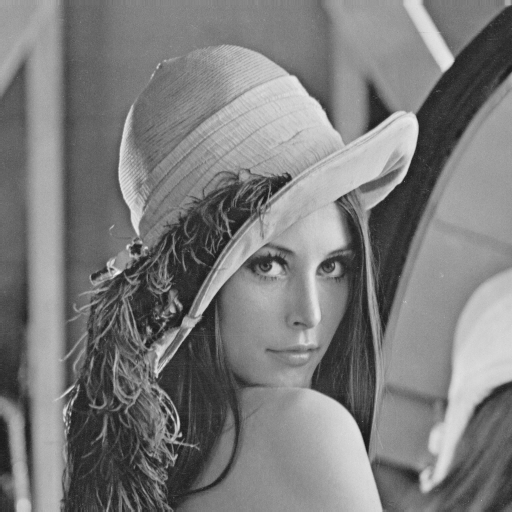

In [6]:
import cv2
from google.colab.patches import cv2_imshow

# 이미지 불러오기 및 RGB 변환
Img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena.jpg')
RGB_Img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 그레이스케일로 변환
gImg= cv2.cvtColor(RGB_Img, cv2.COLOR_RGB2GRAY)
print(Img.shape)
cv2_imshow(gImg)

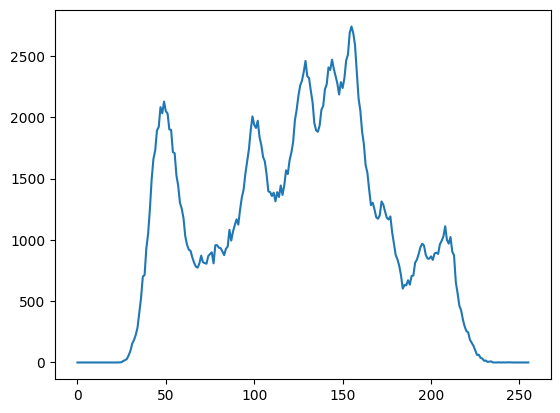

In [8]:
hist = cv2.calcHist([gImg], [0], None, [256], [0, 256])
plt.plot(hist)

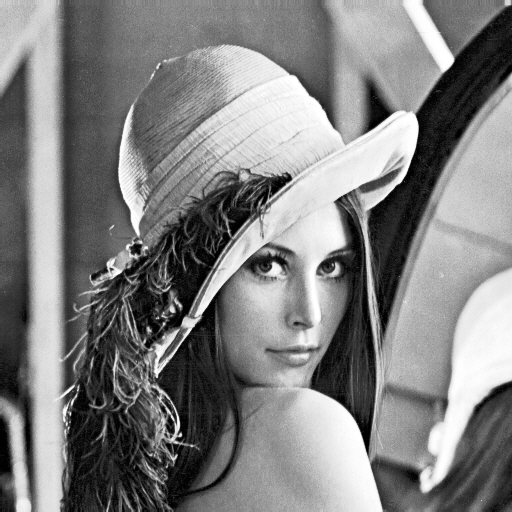

In [9]:
gOut = cv2.equalizeHist(gImg)
cv2_imshow(gOut)

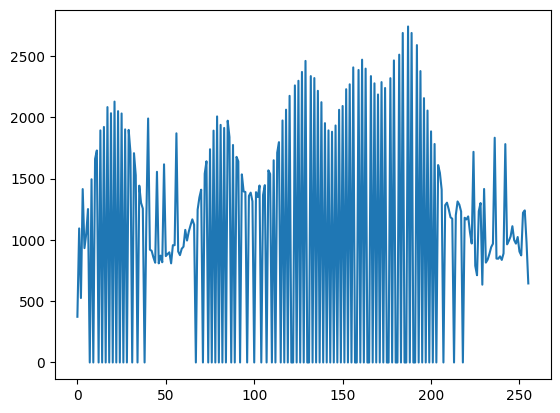

In [12]:
hist2 = cv2.calcHist([gOut], [0], None, [256], [0, 256])
plt.plot(hist2)

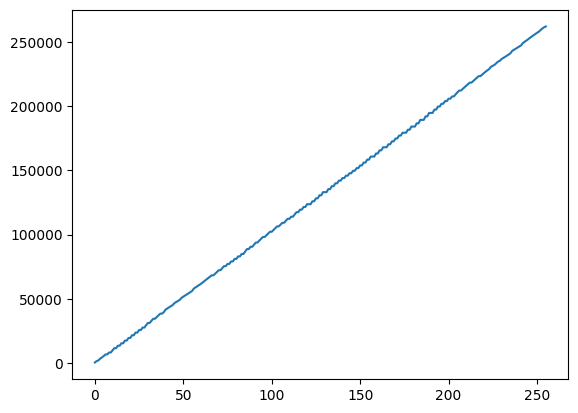

In [14]:
cumlHist = hist2.copy()
for i in range(1, len(cumlHist)):
  cumlHist[i] = cumlHist[i-1] + cumlHist[i]
plt.plot(cumlHist)

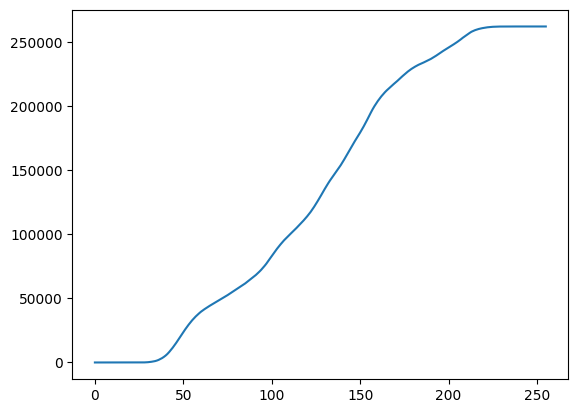

In [17]:
#히스토그램 누적
eqHist = hist.copy()

for i in range(len(eqHist)):
  eqHist[i] = eqHist[i-1] + hist[i]
plt.plot(eqHist)

In [18]:
numOfPixels = np.int32(gImg.shape[0] * gImg.shape[1])
print(numOfPixels)


262144


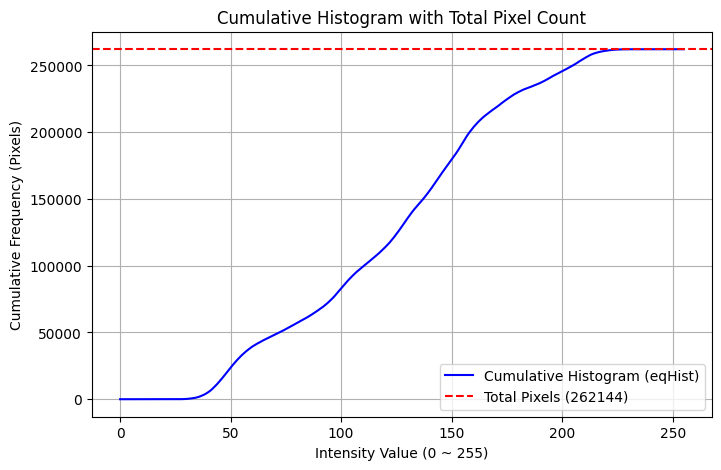

In [19]:
import matplotlib.pyplot as plt

# 누적 히스토그램 그리기
plt.figure(figsize=(8, 5))
plt.plot(eqHist, label='Cumulative Histogram (eqHist)', color='blue')

# 총 픽셀 수(numOfPixels) 위치에 수평선 추가
plt.axhline(y=numOfPixels, color='red', linestyle='--', label=f'Total Pixels ({numOfPixels})')

plt.title('Cumulative Histogram with Total Pixel Count')
plt.xlabel('Intensity Value (0 ~ 255)')
plt.ylabel('Cumulative Frequency (Pixels)')
plt.legend()
plt.grid(True)
plt.show()

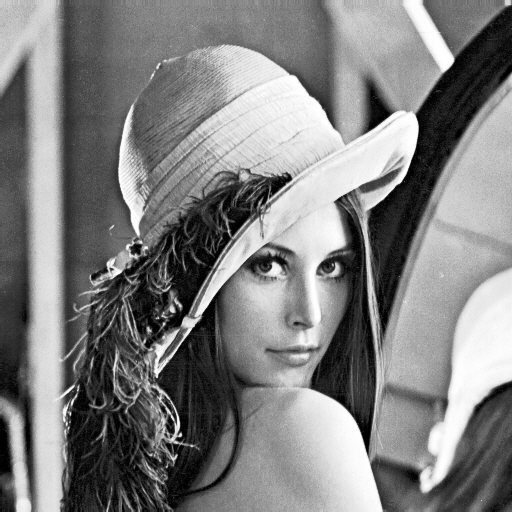

In [23]:
# 1. 누적 히스토그램을 0 ~ 255 범위로 정규화
nj_eqHist = (eqHist - eqHist.min()) * 255 / (eqHist.max() - eqHist.min())
nj_eqHist = nj_eqHist.astype('uint8')

# 2. 정규화된 매핑 테이블을 사용하여 평활화 이미지 생성
gOut1 = gImg.copy()
for i in range(gImg.shape[0]):
  for j in range(gImg.shape[1]):
    gOut1[i, j] = nj_eqHist[gImg[i, j]]

# 3. 결과 출력
cv2_imshow(gOut1)